   Day       Date            Task  Status
 Day 1 2026-11-24    Maths - Ch 1    Done
 Day 2 2026-11-25    Maths - Ch 2    Done
 Day 3 2026-11-26    Maths - Ch 3 Pending
 Day 4 2026-11-27    Maths - Ch 4 Pending
 Day 5 2026-11-28   Python - Ch 1 Pending
 Day 6 2026-11-29   Python - Ch 2 Pending
 Day 7 2026-11-30   Python - Ch 3 Pending
 Day 8 2026-12-01   Python - Ch 4 Pending
 Day 9 2026-12-02   Python - Ch 5 Pending
Day 10 2026-12-03 Computer - Ch 1 Pending
Day 11 2026-12-04 Computer - Ch 2 Pending
Day 12 2026-12-05 Computer - Ch 3 Pending
Day 13 2026-12-06 Computer - Ch 4 Pending
Day 14 2026-12-07  English - Ch 1 Pending
Day 15 2026-12-08  English - Ch 2 Pending
Day 16 2026-12-09  English - Ch 3 Pending
      SMART EXAM PLANNER - DASHBOARD
Exam Date      : 2026-12-20
Days Left      : 26 days
Total Days     : 16 | Done: 2 | Pending: 14
Progress       : 12.5%

📌 TODAY'S TASK: Maths - Ch 1


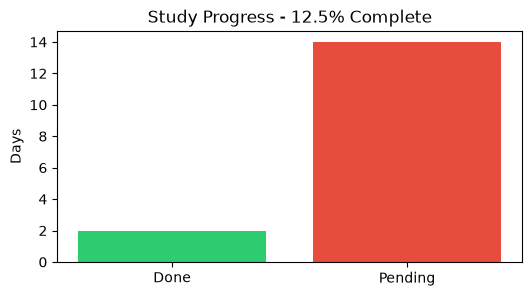


✅ Plan saved as my_study_plan.csv


In [3]:
# SMART EXAM PLANNER - Professional Version
# Author: Sunitha Barik
# Description: Creates day-wise study plan based on exam date and difficulty

import pandas as pd
import matplotlib.pyplot as plt
from datetime import date, timedelta
import math

# ---------------- CONFIG ----------------
TODAY = date.today()
EXAM_DATE = date(2026, 12, 20)
REVISION_DAYS = 3

SUBJECTS = [
    {"Subject": "Python", "Chapters": 5, "Difficulty": "Medium", "Priority": 2},
    {"Subject": "Maths", "Chapters": 4, "Difficulty": "Hard", "Priority": 3},
    {"Subject": "English", "Chapters": 3, "Difficulty": "Easy", "Priority": 1},
    {"Subject": "Computer", "Chapters": 4, "Difficulty": "Medium", "Priority": 2},
]

# ---------------- FUNCTIONS ----------------
def get_days_left():
    """Calculate days remaining for exam"""
    return (EXAM_DATE - TODAY).days

def create_study_plan(df):
    """Generate day-wise study plan - Hard subjects first"""
    total_chapters = df["Chapters"].sum()
    study_days = get_days_left() - REVISION_DAYS
    per_day = math.ceil(total_chapters / study_days)

    # Sort by Priority - High to Low
    df_sorted = df.sort_values("Priority", ascending=False)

    all_chapters = []
    for _, row in df_sorted.iterrows():
        for ch in range(1, row["Chapters"] + 1):
            all_chapters.append(f"{row['Subject']} - Ch {ch}")

    plan = []
    for i in range(0, len(all_chapters), per_day):
        day_num = len(plan) + 1
        study_date = TODAY + timedelta(days=day_num - 1)
        task = ", ".join(all_chapters[i:i+per_day])
        plan.append([f"Day {day_num}", study_date, task, "Pending"])

    return pd.DataFrame(plan, columns=["Day", "Date", "Task", "Status"])

def show_dashboard(plan_df):
    """Show progress dashboard with chart"""
    total = len(plan_df)
    done = len(plan_df[plan_df["Status"] == "Done"])
    pending = total - done
    percent = (done / total) * 100 if total > 0 else 0

    print("="*45)
    print("      SMART EXAM PLANNER - DASHBOARD")
    print("="*45)
    print(f"Exam Date      : {EXAM_DATE}")
    print(f"Days Left      : {get_days_left()} days")
    print(f"Total Days     : {total} | Done: {done} | Pending: {pending}")
    print(f"Progress       : {percent:.1f}%")
    print("="*45)

    # Today's Task
    today_row = plan_df[plan_df["Date"] == TODAY]
    if not today_row.empty:
        print(f"\n📌 TODAY'S TASK: {today_row.iloc[0]['Task']}")
    else:
        print("\n📌 TODAY'S TASK: Revision Day!")

    # Chart
    plt.figure(figsize=(6, 3))
    plt.bar(["Done", "Pending"], [done, pending], color=["#2ecc71", "#e74c3c"])
    plt.title(f"Study Progress - {percent:.1f}% Complete")
    plt.ylabel("Days")
    plt.show()

# ---------------- MAIN EXECUTION ----------------
df = pd.DataFrame(SUBJECTS)
plan_df = create_study_plan(df)

# Demo: Mark first 2 days as Done
plan_df.loc[0:1, "Status"] = "Done"

print(plan_df.to_string(index=False))
show_dashboard(plan_df)

# Save plan to CSV - for portfolio proof
plan_df.to_csv("my_study_plan.csv", index=False)
print("\n✅ Plan saved as my_study_plan.csv")

# 📚 Smart Exam Planner

## Problem
Exam paas aane par students ko samajh nahi aata - kya padhe, kab padhe, kitna time bacha hai?

## Solution
Ye Python project exam date aur subjects ke hisaab se automatic Day-wise Study Plan banata hai.
Hard subjects ko pehle priority deta hai aur last 3 din Revision ke liye rakhta hai.

## Features
- Days Left Calculator
- Priority-based Study Plan (Hard -> Easy)
- Today's Task Finder
- Progress Dashboard with Graph
- Auto Save to CSV

## Tech Used
Python, Pandas, Matplotlib, Datetime

## How to Run
1. Exam date aur Subjects badlo
2. Notebook Run karo
3. Apna Daily Plan dekho

Made by Sunitha Barik